In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

PROJECT_DIR = Path.cwd().parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

TRAIN_CSV = PROCESSED_DIR / "train.csv"
VAL_CSV = PROCESSED_DIR / "validation.csv"
TEST_CSV = PROCESSED_DIR / "test.csv"

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 128
BATCH_SIZE = 16
SEED = 42

print("TensorFlow:", tf.__version__)
print("Project directory:", PROJECT_DIR)

TensorFlow: 2.21.0
Project directory: c:\Banana Sense-AI


In [2]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

class_names = sorted(train_df["label"].unique())

label_to_id = {
    label: index for index, label in enumerate(class_names)
}

id_to_label = {
    index: label for label, index in label_to_id.items()
}

print("Classes:", class_names)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Classes: ['Green', 'Overripe', 'Ripe', 'Semi-ripe']
Training images: 573
Validation images: 123
Testing images: 123


In [3]:
def preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

In [4]:
def create_dataset(dataframe, training=False):

    image_paths = dataframe["image_path"].values

    labels = dataframe["label"].map(label_to_id).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(1)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("MobileNetV2 datasets created successfully!")

MobileNetV2 datasets created successfully!


In [5]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully!


In [6]:
base_model.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

Total layers: 154
Trainable layers: 0


In [7]:
inputs = layers.Input(shape=(128, 128, 3))

# Extract features using pretrained MobileNetV2
x = base_model(inputs, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(128, activation="relu")(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

mobilenet_model = models.Model(
    inputs,
    outputs
)

print("MobileNetV2 classifier created successfully!")

MobileNetV2 classifier created successfully!


In [8]:
mobilenet_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


In [10]:
callbacks_mobilenet = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_mobilenetv2.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

print("MobileNetV2 callbacks configured!")

MobileNetV2 callbacks configured!


In [11]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_mobilenet
)

Epoch 1/20


c:\Users\Tejus\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


36/36 ━━━━━━━━━━━━━━━━━━━━ 16s 227ms/step - accuracy: 0.6475 - loss: 0.9196 - val_accuracy: 0.8699 - val_loss: 0.3463
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 147ms/step - accuracy: 0.8168 - loss: 0.4367 - val_accuracy: 0.9024 - val_loss: 0.2536
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 140ms/step - accuracy: 0.8848 - loss: 0.3131 - val_accuracy: 0.9106 - val_loss: 0.2514
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.9058 - loss: 0.2409 - val_accuracy: 0.9268 - val_loss: 0.2543
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 139ms/step - accuracy: 0.9232 - loss: 0.2097 - val_accuracy: 0.9106 - val_loss: 0.2331
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 148ms/step - accuracy: 0.9180 - loss: 0.1947 - val_accuracy: 0.9268 - val_loss: 0.2327
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 10s 136ms/step - accuracy: 0.9407 - loss: 0.1408 - val_accuracy: 0.9187 - val_loss: 0.2233
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 139ms/step - accuracy: 0.9424 - loss: 0.1560 - val_accuracy: 0.9268 - va

In [12]:
BEST_MOBILENET_PATH = MODEL_DIR / "best_mobilenetv2.keras"

best_mobilenet = tf.keras.models.load_model(BEST_MOBILENET_PATH)

print("Best MobileNetV2 model loaded successfully!")

Best MobileNetV2 model loaded successfully!


In [13]:
test_loss_mobilenet, test_accuracy_mobilenet = best_mobilenet.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy_mobilenet * 100:.2f}%")
print(f"Test Loss: {test_loss_mobilenet:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.9268 - loss: 0.1627
Test Accuracy: 92.68%
Test Loss: 0.1627


In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_probs = best_mobilenet.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 312ms/step
              precision    recall  f1-score   support

       Green       1.00      0.97      0.98        32
    Overripe       1.00      0.94      0.97        31
        Ripe       0.81      0.97      0.88        30
   Semi-ripe       0.93      0.83      0.88        30

    accuracy                           0.93       123
   macro avg       0.93      0.93      0.93       123
weighted avg       0.93      0.93      0.93       123



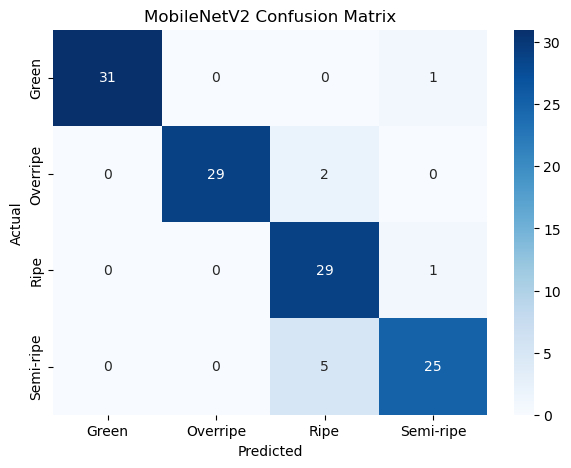

In [15]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

In [16]:
FINAL_MODEL_PATH = MODEL_DIR / "banana_mobilenetv2.keras"

best_mobilenet.save(FINAL_MODEL_PATH)

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [17]:
import tensorflow as tf
import pandas as pd

model_v1 = tf.keras.models.load_model(
    MODEL_DIR / "best_banana_cnn.keras"
)

model_v2 = tf.keras.models.load_model(
    MODEL_DIR / "best_banana_cnn_v2.keras"
)

model_mobilenet = tf.keras.models.load_model(
    MODEL_DIR / "best_mobilenetv2.keras"
)

print("All three models loaded successfully!")

All three models loaded successfully!


In [18]:
results = []

for name, model in [
    ("CNN V1", model_v1),
    ("Improved CNN V2", model_v2),
    ("MobileNetV2", model_mobilenet)
]:
    loss, accuracy = model.evaluate(test_ds, verbose=0)

    results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy * 100, 2),
        "Test Loss": round(loss, 4)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Test Accuracy (%)",
    ascending=False
)

comparison_df

,Model,Test Accuracy (%),Test Loss
2,MobileNetV2,92.68,0.1627
1,Improved CNN V2,50.41,3.3062
0,CNN V1,41.46,15.8140


In [20]:
print(test_df.columns.tolist())
print(test_df.head())

['image_path', 'label', 'split']
                                          image_path      label split
0  C:\Banana Sense-AI\data\raw\Banana Ripeness De...       Ripe  test
1  C:\Banana Sense-AI\data\raw\Banana Ripeness De...       Ripe  test
2  C:\Banana Sense-AI\data\raw\Banana Ripeness De...       Ripe  test
3  C:\Banana Sense-AI\data\raw\Banana Ripeness De...   Overripe  test
4  C:\Banana Sense-AI\data\raw\Banana Ripeness De...  Semi-ripe  test


In [21]:
test_df["label_id"] = test_df["label"].map(label_to_id)

test_ds_cnn = tf.data.Dataset.from_tensor_slices((
    test_df["image_path"].values,
    test_df["label_id"].values
))

test_ds_cnn = test_ds_cnn.map(
    preprocess_cnn_image,
    num_parallel_calls=2
)

test_ds_cnn = test_ds_cnn.batch(16).prefetch(1)

In [22]:
loss_v1, acc_v1 = model_v1.evaluate(test_ds_cnn)
loss_v2, acc_v2 = model_v2.evaluate(test_ds_cnn)

print(f"CNN V1 Accuracy: {acc_v1 * 100:.2f}%")
print(f"CNN V2 Accuracy: {acc_v2 * 100:.2f}%")



8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8862 - loss: 0.2465
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9431 - loss: 0.1636
CNN V1 Accuracy: 88.62%
CNN V2 Accuracy: 94.31%


In [23]:
FINAL_MODEL_PATH = MODEL_DIR / "banana_sense_ai_final.keras"

model_v2.save(FINAL_MODEL_PATH)

print("Final BananaSense AI model saved successfully!")

Final BananaSense AI model saved successfully!
